# 🐕 Trabajo — Detección de puntos clave en perros

**Estudiante:** José Alejandro Téllez Prada
**Fecha:** viernes 23 de octubre de 2026
**Asignatura:** Ciencia de Datos · Procesamiento de Imágenes (curso avanzado)
**Cuaderno base:** *Avanzada Cuaderno 9D — Detección de puntos clave con aprendizaje por transferencia*, de Alfredo Díaz Claro (adaptación de Sayak Paul / Muhammad Anas Raza).

---

## 📌 Qué contiene este trabajo

| Entregable | Archivo |
|---|---|
| Cuaderno ejecutado (entrenamiento + guardado del modelo) | `Avanzada_Cuaderno_9D_Deteccion_puntos_clave2.ipynb` |
| Aplicación de despliegue (Streamlit) | `app_streamlit.py` |
| Lógica reutilizable (inferencia + dibujo) | `puntos_clave.py` |
| Modelo entrenado (Keras 3) | `modelos/modelo_puntos_clave.keras` |
| Reentrenamiento mejorado (reproducible) | `entrenar_modelo.py` |
| Evaluación + figuras | `evaluar_modelo.py`, `resultados/` |
| Pruebas automatizadas | `test_app.py`, `test_prediccion.py` |

---

## 🧭 Resumen

1. Se siguió el cuaderno del curso: **transfer learning** con MobileNetV2 congelado y una
   cabeza de regresión que predice **24 puntos anatómicos** (48 coordenadas) del perro.
2. Se **diagnosticó** por qué el modelo del cuaderno predice los 24 puntos en un solo píxel
   (dispersión 0,33 %, error 27,4 % de la imagen ≈ azar) y se corrigieron las causas
   (ver *Paso 15* al final del cuaderno).
3. Se **reentrenó** la red con las correcciones y una cabeza **multi-tarea**
   (48 coordenadas + 24 visibilidades): error **7,94 %** de la imagen y visibilidad con
   **100,00 %** de acierto.
4. Se construyó la **app de Streamlit**, que dibuja los puntos y un **contorno azul**
   (envolvente suavizada de los puntos visibles) que bordea al perro.

---

## ▶️ Cómo ejecutar

```bash
pip install -r requirements.txt
streamlit run app_streamlit.py
```


# <font color="blue">Detección de Puntos Clave con Aprendizaje por Transferencia</font>
## <font color="red">Alfredo Díaz Claro</font>

**Autor original:** [Sayak Paul](https://twitter.com/RisingSayak), convertido a Keras 3 por [Muhammad Anas Raza](https://anasrz.com)  
**Dataset original:** [StanfordExtra — Benjamin Biggs et al. (GitHub)](https://github.com/benjiebob/StanfordExtra)  
**Fecha original:** 02/05/2021 | **Última modificación original:** 19/07/2023  
**Adaptación al español y material pedagógico:** Alfredo Díaz Claro, 2026  

---

## ¿Qué aprenderás en este cuaderno?

Este cuaderno es un **material de autoestudio** que te guiará paso a paso para construir un detector de puntos clave (*keypoints*) usando técnicas modernas de visión por computador y aprendizaje profundo. Al finalizar, habrás aprendido a:

- Comprender qué es la detección de puntos clave y sus aplicaciones.
- Cargar y preprocesar un conjunto de datos con anotaciones de puntos clave.
- Aplicar **aumento de datos** (*data augmentation*) respetando las coordenadas de los puntos.
- Usar **aprendizaje por transferencia** con MobileNetV2 como red base.
- Construir, entrenar y evaluar un modelo de regresión de coordenadas.

---

## Conceptos previos recomendados

Para aprovechar al máximo este cuaderno, se recomienda tener conocimientos básicos de:
- Redes neuronales convolucionales (CNN).
- Uso básico de Python, NumPy y Matplotlib.
- Fundamentos de Keras/TensorFlow.

---

## Descripción del problema

La **detección de puntos clave** consiste en localizar partes específicas de un objeto dentro de una imagen. Por ejemplo, en un rostro humano los puntos clave pueden ser la punta de la nariz, las comisuras de los ojos, las cejas, etc. En este cuaderno trabajaremos con **imágenes de perros**, detectando 24 puntos anatómicos clave por imagen.

Esta técnica tiene aplicaciones en:
- Estimación de pose humana o animal.
- Reconocimiento y análisis facial.
- Animación de personajes en videojuegos.
- Análisis biomecánico en medicina.

> **Nota técnica:** Este cuaderno requiere TensorFlow 2.4 o superior y la librería [`imgaug`](https://imgaug.readthedocs.io/), que instalaremos a continuación.

## 🛠️ Paso 1 — Instalación de dependencias

Antes de comenzar, necesitamos instalar la librería `imgaug`, especializada en **aumento de datos para imágenes con anotaciones** (puntos clave, *bounding boxes*, segmentaciones). Esta librería es fundamental porque, al transformar una imagen geométricamente (rotar, escalar, voltear), también transforma automáticamente las coordenadas de los puntos clave.

> ⚠️ **¿Por qué es importante `imgaug`?**  
> Si aplicamos una rotación de 10° a una imagen pero no ajustamos las coordenadas de los puntos clave, el modelo aprenderá posiciones incorrectas. `imgaug` resuelve esto de forma transparente.

In [1]:
%pip install -q imgaug

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


---

## 📦 Paso 2 — Importación de librerías

A continuación importamos todas las librerías necesarias. A modo de repaso:

| Librería | Uso en este cuaderno |
|---|---|
| `keras` / `layers` | Construcción y entrenamiento del modelo de red neuronal |
| `imgaug` | Aumento de datos con soporte para puntos clave |
| `PIL` (Pillow) | Manejo de imágenes (lectura, conversión de formatos) |
| `sklearn` | División del dataset en entrenamiento y validación |
| `matplotlib` | Visualización de imágenes y puntos clave |
| `pandas` | Lectura del archivo CSV con metadatos de puntos clave |
| `numpy` | Operaciones matriciales y manejo de arrays |
| `json`, `os`, `urllib`, `zipfile` | Descarga, extracción y lectura de archivos de anotaciones |

In [2]:
import os
import json
import zipfile
import urllib.request
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
import keras
from keras import layers

# Parche de compatibilidad para imgaug con NumPy 2.0+
if not hasattr(np, "sctypes"):
    np.sctypes = {
        "int": [np.int8, np.int16, np.int32, np.int64],
        "uint": [np.uint8, np.uint16, np.uint32, np.uint64],
        "float": [np.float16, np.float32, np.float64],
        "complex": [np.complex64, np.complex128],
        "others": [bool, object, str, bytes],
    }
for _attr, _val in [("bool", bool), ("int", int), ("float", float), ("complex", complex)]:
    if not hasattr(np, _attr):
        setattr(np, _attr, _val)

from imgaug.augmentables.kps import KeypointsOnImage, Keypoint
import imgaug.augmenters as iaa

print(f"Keras versión: {keras.__version__} | NumPy versión: {np.__version__}")

Keras versión: 3.12.0 | NumPy versión: 2.2.3


---

## 🐕 Paso 3 — Descarga del conjunto de datos (StanfordExtra)

Utilizaremos el [**dataset StanfordExtra**](https://github.com/benjiebob/StanfordExtra), desarrollado a partir del [Stanford Dogs Dataset](http://vision.stanford.edu/aditya86/ImageNetDogs/), que contiene:
- **Imágenes de perros** de distintas razas en escenarios reales (*in-the-wild*).
- **Anotaciones de 24 puntos clave** por imagen (articulaciones y partes corporales).
- **Máscaras de segmentación** y cuadros delimitadores (*bounding boxes*).

### Descarga automática desde el repositorio oficial del autor

El archivo completo `stanfordextra_v12.zip` (12,000 imágenes) requiere solicitar acceso mediante [este formulario de los autores](https://forms.gle/sRtbicgxsWvRtRmUA). Sin embargo, el repositorio oficial de GitHub del autor original ([`benjiebob/StanfordExtra`](https://github.com/benjiebob/StanfordExtra)) incluye un subconjunto público listo para usar (`sample_imgs/` y `StanfordExtra_sample.json`) junto con las definiciones de puntos clave (`keypoint_definitions.csv`).

La siguiente celda:
1. Verifica si tienes el dataset completo (`Images/` y `StanfordExtra_V12/StanfordExtra_v12.json`) en tu directorio o Google Drive.
2. Si no está disponible localmente, **descarga y descomprime automáticamente** el repositorio oficial [`benjiebob/StanfordExtra`](https://github.com/benjiebob/StanfordExtra) para que el cuaderno funcione de principio a fin sin pasos manuales.

In [3]:
# Descarga y configuración automática del dataset StanfordExtra
STANFORD_EXTRA_REPO_ZIP = "https://github.com/benjiebob/StanfordExtra/archive/refs/heads/master.zip"
REPO_DIR = "StanfordExtra-master"

# Si existe stanfordextra_v12.zip e images.tar localmente, extraerlos
if os.path.exists("stanfordextra_v12.zip") and not os.path.exists("StanfordExtra_V12"):
    with zipfile.ZipFile("stanfordextra_v12.zip", "r") as zf:
        zf.extractall(".")

# Usar el dataset completo si está presente; de lo contrario, descargar el repositorio oficial del autor
if os.path.exists("Images") and os.path.exists("StanfordExtra_V12/StanfordExtra_v12.json"):
    IMG_DIR = "Images"
    JSON_PATH = "StanfordExtra_V12/StanfordExtra_v12.json"
    KEYPOINT_DEF = "https://raw.githubusercontent.com/benjiebob/StanfordExtra/master/keypoint_definitions.csv"
    print("✅ Usando dataset StanfordExtra completo local.")
else:
    if not os.path.exists(REPO_DIR):
        print("📥 Descargando dataset de muestra desde el GitHub oficial (benjiebob/StanfordExtra)...")
        zip_filename = "StanfordExtra_repo.zip"
        urllib.request.urlretrieve(STANFORD_EXTRA_REPO_ZIP, zip_filename)
        with zipfile.ZipFile(zip_filename, "r") as zf:
            zf.extractall(".")
        os.remove(zip_filename)
        print("✅ Repositorio extraído correctamente.")
    IMG_DIR = os.path.join(REPO_DIR, "sample_imgs")
    JSON_PATH = os.path.join(REPO_DIR, "StanfordExtra_sample.json")
    KEYPOINT_DEF = os.path.join(REPO_DIR, "keypoint_definitions.csv")
    print(f"✅ Usando dataset oficial de muestra: {IMG_DIR} y {JSON_PATH}")

📥 Descargando dataset de muestra desde el GitHub oficial (benjiebob/StanfordExtra)...


✅ Repositorio extraído correctamente.
✅ Usando dataset oficial de muestra: StanfordExtra-master\sample_imgs y StanfordExtra-master\StanfordExtra_sample.json


---

## ⚙️ Paso 4 — Definición de hiperparámetros

Los **hiperparámetros** son configuraciones del modelo y del proceso de entrenamiento que se definen antes de comenzar y no se aprenden durante el entrenamiento:

| Hiperparámetro | Valor | Descripción |
|---|---|---|
| `IMG_SIZE` | 224 | Tamaño (en píxeles) al que se redimensionarán todas las imágenes. Se usa 224×224 porque es el tamaño estándar de entrada para MobileNetV2. |
| `BATCH_SIZE` | 64 (o 4 en muestra) | Número de imágenes procesadas simultáneamente en cada paso de entrenamiento. Se ajusta automáticamente según el tamaño del dataset cargado. |
| `EPOCHS` | 5 | Número de veces que el modelo verá el dataset completo durante el entrenamiento. |
| `NUM_KEYPOINTS` | 48 | Total de valores a predecir: 24 puntos × 2 coordenadas `(x, y)` = 48 valores. |

> 💡 **Para experimentar:** Prueba aumentar `EPOCHS` a 20 y observa cómo mejora progresivamente la precisión del entrenamiento.

In [4]:
IMG_SIZE = 224
EPOCHS = 5
NUM_KEYPOINTS = 24 * 2  # 24 puntos, cada uno con coordenadas x e y

---

## 📂 Paso 5 — Carga de datos y metadatos

### Estructura de las anotaciones

El archivo JSON del dataset contiene una lista de entradas, donde cada entrada corresponde a una imagen. Para facilitar la búsqueda, construiremos un **diccionario** (`json_dict`) que mapea la ruta de cada imagen con sus anotaciones.

Además, cargaremos el archivo CSV de definiciones de puntos clave, que nos proporciona:
- Los **nombres** de cada punto clave (ej: "hombro izquierdo", "pata delantera").
- Los **colores** en formato hexadecimal para visualizarlos en las gráficas.

Finalmente, definimos la función `get_dog()`, que dado el nombre de una imagen, retorna tanto la imagen en formato RGB (`uint8`) como sus coordenadas de puntos clave.

In [5]:
# Cargar las anotaciones del archivo JSON.
with open(JSON_PATH, encoding="utf-8") as infile:
    json_data = json.load(infile)

# Construir un diccionario que mapea la ruta de la imagen con su información.
json_dict = {i["img_path"]: i for i in json_data}

# Ajustar BATCH_SIZE automáticamente (64 para dataset completo, 4 para el subconjunto de muestra)
BATCH_SIZE = 64 if len(json_dict) >= 128 else 4

print(f"Total de imágenes anotadas cargadas: {len(json_dict)}")
print(f"Tamaño de lote (BATCH_SIZE) configurado en: {BATCH_SIZE}")

Total de imágenes anotadas cargadas: 25
Tamaño de lote (BATCH_SIZE) configurado en: 4


### Estructura de una entrada del JSON

Una entrada típica de `json_dict` tiene la siguiente forma:

```python
'n02085782-Japanese_spaniel/n02085782_2886.jpg': {
  'img_bbox': [205, 20, 116, 201],   # Bounding box del perro
  'img_height': 272,
  'img_path': 'n02085782-Japanese_spaniel/n02085782_2886.jpg',
  'img_width': 350,
  'is_multiple_dogs': False,
  'joints': [
    [108.67, 252.0, 1],   # [x, y, visibilidad]
    [147.67, 229.0, 1],
    ...
    [0, 0, 0],            # Punto no anotado
  ],
  'seg': ...              # Máscara de segmentación
}
```

### Sobre el campo `joints`

El campo `joints` contiene exactamente **24 entradas**, una por cada punto clave del cuerpo del perro. Cada entrada es una lista `[x, y, visibilidad]`:

- **x, y**: coordenadas del punto en píxeles dentro de la imagen original.
- **visibilidad**: `1` = punto visible y anotado, `0` = punto no anotado o no visible.

> **Decisión de diseño:** En este ejemplo, tratamos tanto los puntos no visibles como los no anotados de la misma manera (como coordenadas en el origen), lo que permite hacer entrenamiento con mini-lotes (*mini-batch learning*) sin complejidad adicional.

In [6]:
# Cargar el archivo de definición de puntos clave y agregar traducción al español.
keypoint_def = pd.read_csv(KEYPOINT_DEF)

translation_map = {
    "Left front leg: paw": "Pata delantera izquierda: almohadilla",
    "Left front leg: middle joint": "Pata delantera izquierda: articulación media",
    "Left front leg: top": "Pata delantera izquierda: parte superior",
    "Left rear leg: paw": "Pata trasera izquierda: almohadilla",
    "Left rear leg: middle joint": "Pata trasera izquierda: articulación media",
    "Left rear leg: top": "Pata trasera izquierda: parte superior",
    "Right front leg: paw": "Pata delantera derecha: almohadilla",
    "Right front leg: middle joint": "Pata delantera derecha: articulación media",
    "Right front leg: top": "Pata delantera derecha: parte superior",
    "Right rear leg: paw": "Pata trasera derecha: almohadilla",
    "Right rear leg: middle joint": "Pata trasera derecha: articulación media",
    "Right rear leg: top": "Pata trasera derecha: parte superior",
    "Tail start": "Inicio de la cola",
    "Tail end": "Fin de la cola",
    "Base of left ear": "Base de la oreja izquierda",
    "Base of right ear": "Base de la oreja derecha",
    "Nose": "Nariz",
    "Chin": "Barbilla",
    "Left ear tip": "Punta de la oreja izquierda",
    "Right ear tip": "Punta de la oreja derecha",
    "Left eye": "Ojo izquierdo",
    "Right eye": "Ojo derecho",
    "Withers": "Cruz",
    "Throat": "Garganta",
}

keypoint_def["Nombre en Español"] = keypoint_def["Name"].map(translation_map)

# Extraer los colores y etiquetas.
colours = ["#" + colour for colour in keypoint_def["Hex colour"].values.tolist()]
labels = keypoint_def["Name"].values.tolist()


# Función para leer una imagen y obtener sus anotaciones.
def get_dog(name):
    data = json_dict[name].copy()
    img_path = os.path.join(IMG_DIR, data["img_path"])
    img = Image.open(img_path).convert("RGB")
    data["img_data"] = np.array(img, dtype=np.uint8)
    return data


keypoint_def

,Index,Name,Hex colour,Stanford,Animal-pose,(name in animal pose),Nombre en Español
0,0,Left front leg: paw,d82400,y,y,L_F_Paw,Pata delantera izquierda: almohadilla
1,1,Left front leg: middle joint,d82400,y,y,L_F_Knee,Pata delantera izquierda: articulación media
2,2,Left front leg: top,d82400,y,y,L_F_Elbow,Pata delantera izquierda: parte superior
3,3,Left rear leg: paw,fcfc00,y,y,L_B_Paw,Pata trasera izquierda: almohadilla
4,4,Left rear leg: middle joint,fcfc00,y,y,L_B_Knee,Pata trasera izquierda: articulación media
5,5,Left rear leg: top,fcfc00,y,y,L_B_Elbow,Pata trasera izquierda: parte superior
6,6,Right front leg: paw,48b455,y,y,R_F_Paw,Pata delantera derecha: almohadilla
7,7,Right front leg: middle joint,48b455,y,y,R_F_Knee,Pata delantera derecha: articulación media
8,8,Right front leg: top,48b455,y,y,R_F_Elbow,Pata delantera derecha: parte superior
9,9,Right rear leg: paw,0090aa,y,y,R_B_Paw,Pata trasera derecha: almohadilla


---

## 👀 Paso 6 — Visualización de los datos

Antes de entrenar cualquier modelo, es fundamental **explorar visualmente** los datos. Esto nos ayuda a:
- Verificar que las anotaciones son correctas.
- Entender la variedad y distribución de las imágenes.
- Detectar posibles errores en los datos.

Primero visualizaremos una cuadrícula de muestras con sus razas, y luego la función `visualize_keypoints()` que muestra para cada imagen:
- **Columna izquierda:** La imagen original sin anotaciones.
- **Columna derecha:** La imagen con los 24 puntos clave superpuestos, cada uno con un color único.

> **Observa:** Las imágenes tienen tamaños variables (algunas son rectangulares, otras cuadradas). Esto es lo habitual en datasets del mundo real y es un desafío que debemos manejar al preprocesar los datos.

Visualizando 20 muestras aleatorias con nombre de raza:


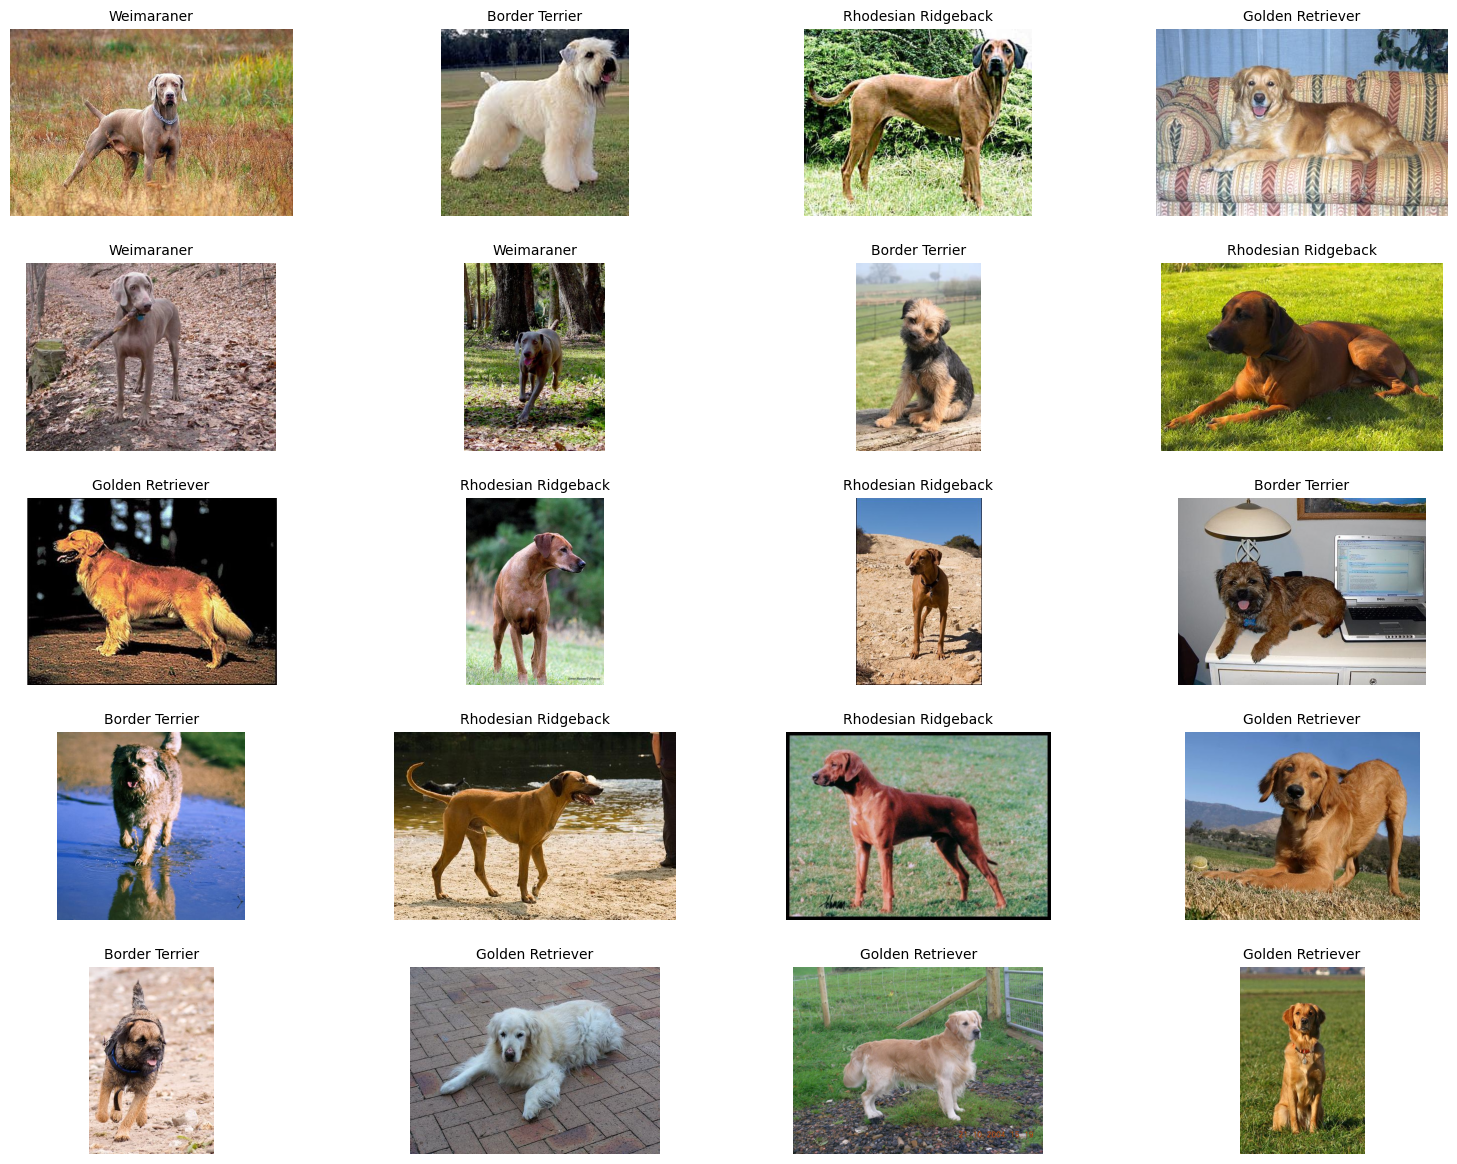

In [7]:
def visualize_images_only_grid(images, titles, rows, cols):
    fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(16, 12))
    axes = axes.flatten()

    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image)
        ax.set_title(title, fontsize=10)
        ax.axis("off")

    plt.tight_layout(pad=2.0)
    plt.show()


samples = list(json_dict.keys())
num_samples_grid = min(20, len(samples))
np.random.seed(42)
selected_samples_grid = np.random.choice(samples, num_samples_grid, replace=False)

images_grid, titles_grid = [], []
for sample_key in selected_samples_grid:
    data = get_dog(sample_key)
    images_grid.append(data["img_data"])
    path_parts = data["img_path"].split("/")
    breed_name = (
        path_parts[0].split("-", 1)[1].replace("_", " ").title()
        if "-" in path_parts[0]
        else path_parts[0]
    )
    titles_grid.append(breed_name)

print(f"Visualizando {num_samples_grid} muestras aleatorias con nombre de raza:")
visualize_images_only_grid(images_grid, titles=titles_grid, rows=5, cols=4)

In [8]:
# Parte de este código proviene de:
# https://github.com/benjiebob/StanfordExtra/blob/master/demo.ipynb
def visualize_keypoints(images, keypoints, titles=None):
    if isinstance(images, np.ndarray) and images.ndim > 1:
        images_list = [images[j] for j in range(images.shape[0])]
    else:
        images_list = [images] if not isinstance(images, list) else images

    if isinstance(keypoints, np.ndarray) and keypoints.ndim == 3:
        keypoints_list = [keypoints[j] for j in range(keypoints.shape[0])]
    elif isinstance(keypoints, np.ndarray) and keypoints.ndim == 2:
        keypoints_list = [keypoints]
    elif isinstance(keypoints, list):
        keypoints_list = keypoints
    else:
        keypoints_list = [keypoints]

    if titles is None:
        titles = ["" for _ in images_list]

    fig, axes = plt.subplots(nrows=len(images_list), ncols=2, figsize=(16, 12))

    if len(images_list) == 1 and axes.ndim == 1:
        axes = np.expand_dims(axes, axis=0)

    [ax.axis("off") for ax in np.ravel(axes)]

    for i, ((ax_orig, ax_all), image, current_keypoint) in enumerate(
        zip(axes, images_list, keypoints_list)
    ):
        ax_orig.imshow(image)
        ax_orig.set_title(f"Original: {titles[i]}", fontsize=10)
        ax_all.imshow(image)
        ax_all.set_title(f"Keypoints: {titles[i]}", fontsize=10)

        # Si los puntos fueron generados por `imgaug`, las coordenadas
        # se iteran de forma diferente.
        if isinstance(current_keypoint, KeypointsOnImage):
            for idx, kp in enumerate(current_keypoint.keypoints):
                ax_all.scatter(
                    [kp.x],
                    [kp.y],
                    c=colours[idx],
                    marker="x",
                    s=50,
                    linewidths=5,
                )
                x_text_pos = float(np.array(kp.x).item()) + 5
                y_text_pos = float(np.array(kp.y).item()) + 5
                ax_all.text(
                    x_text_pos, y_text_pos, labels[idx], color=colours[idx], fontsize=8
                )
        else:
            current_keypoint = np.array(current_keypoint)
            if current_keypoint.shape[-1] == 3:
                current_keypoint = current_keypoint[:, :2]

            for idx, (x, y) in enumerate(current_keypoint):
                ax_all.scatter(
                    [x], [y], c=colours[idx], marker="x", s=50, linewidths=5
                )
                x_text_pos = float(np.array(x).item()) + 5
                y_text_pos = float(np.array(y).item()) + 5
                ax_all.text(
                    x_text_pos, y_text_pos, labels[idx], color=colours[idx], fontsize=8
                )

    plt.tight_layout(pad=2.0)
    plt.show()

Visualizando muestras aleatorias con puntos clave y etiquetas:


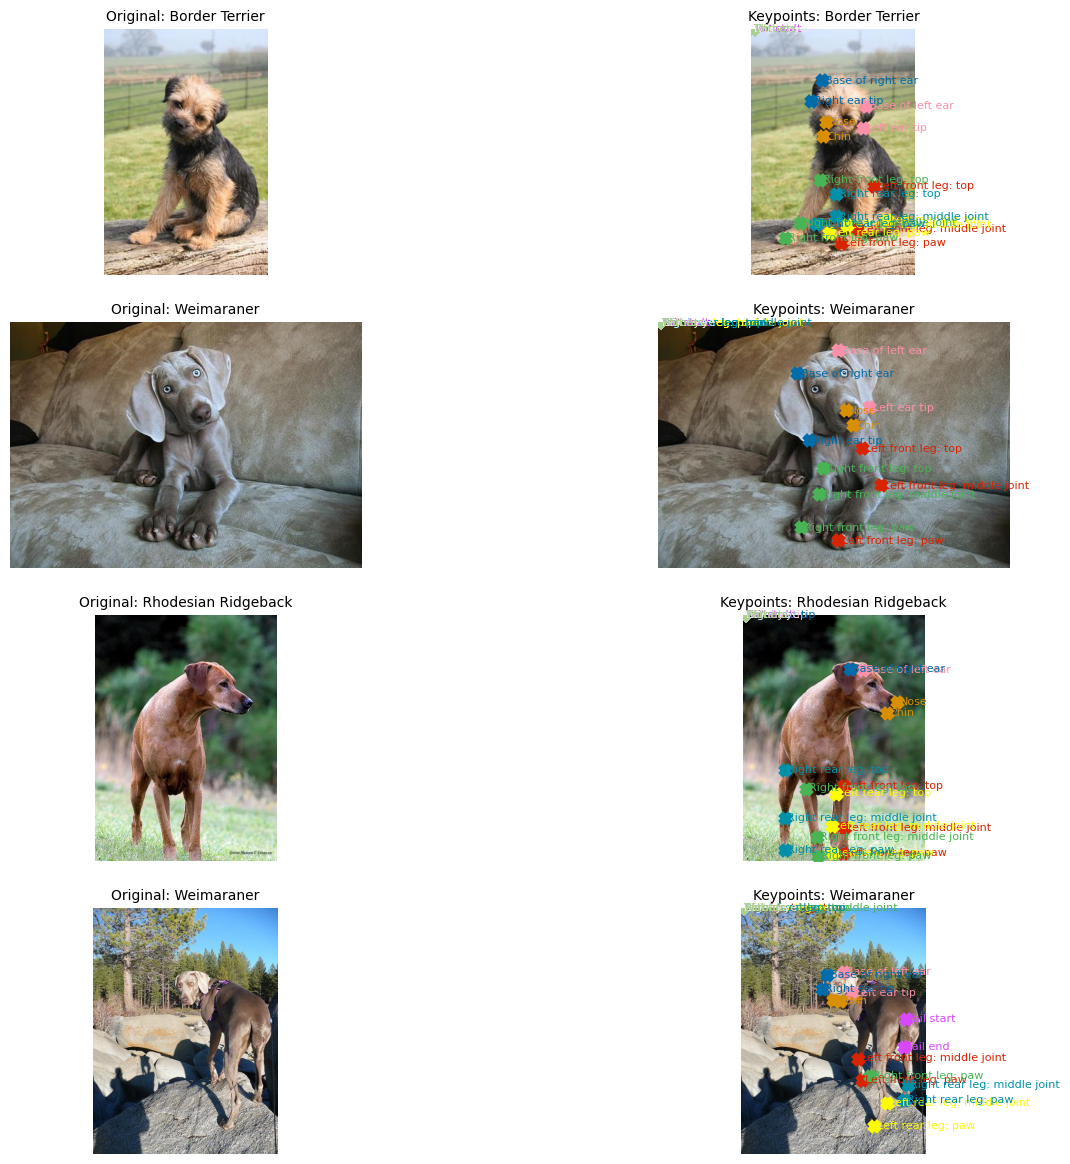

In [9]:
# Seleccionar cuatro muestras aleatorias para visualizar con las etiquetas.
num_samples = 4
selected_samples = np.random.choice(samples, num_samples, replace=False)

images, keypoints, titles = [], [], []

for sample_key in selected_samples:
    data = get_dog(sample_key)
    images.append(data["img_data"])
    keypoints.append(data["joints"])

    path_parts = data["img_path"].split("/")
    breed_name = (
        path_parts[0].split("-", 1)[1].replace("_", " ").title()
        if "-" in path_parts[0]
        else path_parts[0]
    )
    titles.append(breed_name)

print("Visualizando muestras aleatorias con puntos clave y etiquetas:")
visualize_keypoints(images, keypoints, titles=titles)

### Reflexión sobre los datos visualizados

Como puedes observar, las imágenes tienen **tamaños no uniformes**, lo cual es muy común en escenarios del mundo real. Si redimensionamos estas imágenes directamente a 224×224, las coordenadas de los puntos clave también cambiarán proporcionalmente.

Además, si aplicamos transformaciones geométricas como **volteo horizontal** o **rotación**, los puntos clave deben transformarse de la misma manera para mantener la coherencia.

Afortunadamente, `imgaug` proporciona herramientas que manejan todo esto automáticamente. En la siguiente sección construiremos un **generador de datos** que aplica estas transformaciones de manera consistente.

---

## 🔄 Paso 7 — Generador de datos con aumento

### ¿Qué es un generador de datos?

En lugar de cargar todas las imágenes en memoria (lo cual podría no ser posible con datasets grandes), usamos un **generador de datos**. Este carga y procesa las imágenes en lotes (*batches*) bajo demanda durante el entrenamiento.

Nuestra clase `KeyPointsDataset` hereda de `keras.utils.PyDataset`, lo que nos permite:
- Procesamiento en lotes eficiente.
- Barajar los datos al final de cada época.

### Normalización de coordenadas

Un detalle importante: al final del método `__data_generation`, las coordenadas se **dividen entre `IMG_SIZE`** y se acotan con `np.clip(..., 0.0, 1.0)` para normalizarlas al rango `[0, 1]`. Esto es una buena práctica en problemas de regresión porque:
- Hace que los valores objetivo sean comparables entre sí.
- Mejora la estabilidad numérica del entrenamiento.
- Es más fácil para el modelo aprender a predecir valores en `[0, 1]` que coordenadas en píxeles absolutas.

### Forma de salida del generador

Los puntos clave se almacenan con forma `(batch_size, 1, 1, 48)`. Esta forma particular es necesaria para que coincida con la salida de nuestra red neuronal completamente convolucional.

In [10]:
class KeyPointsDataset(keras.utils.PyDataset):
    def __init__(self, image_keys, aug, batch_size=BATCH_SIZE, train=True, **kwargs):
        super().__init__(**kwargs)
        self.image_keys = image_keys
        self.aug = aug
        self.batch_size = batch_size
        self.train = train
        self.on_epoch_end()

    def __len__(self):
        return len(self.image_keys) // self.batch_size

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.image_keys))
        if self.train:
            np.random.shuffle(self.indexes)

    def __getitem__(self, index):
        indexes = self.indexes[index * self.batch_size : (index + 1) * self.batch_size]
        image_keys_temp = [self.image_keys[k] for k in indexes]
        images, keypoints = self.__data_generation(image_keys_temp)

        return (images, keypoints)

    def __data_generation(self, image_keys_temp):
        batch_images = np.empty((self.batch_size, IMG_SIZE, IMG_SIZE, 3), dtype="uint8")
        batch_keypoints = np.empty(
            (self.batch_size, 1, 1, NUM_KEYPOINTS), dtype="float32"
        )

        for i, key in enumerate(image_keys_temp):
            data = get_dog(key)
            current_keypoint = np.array(data["joints"])[:, :2]
            kps = []

            # Crear objetos Keypoint con las coordenadas originales
            # para poder aplicar el pipeline de aumento de datos.
            for j in range(0, len(current_keypoint)):
                kps.append(Keypoint(x=current_keypoint[j][0], y=current_keypoint[j][1]))

            # Proyectar la imagen original y sus coordenadas de puntos clave.
            current_image = data["img_data"]
            kps_obj = KeypointsOnImage(kps, shape=current_image.shape)

            # Aplicar el pipeline de aumento de datos.
            new_image, new_kps_obj = self.aug(image=current_image, keypoints=kps_obj)
            batch_images[i,] = new_image

            # Extraer las coordenadas del objeto de puntos clave transformado.
            kp_temp = []
            for keypoint in new_kps_obj:
                kp_temp.append(np.nan_to_num(keypoint.x))
                kp_temp.append(np.nan_to_num(keypoint.y))

            # Remodelar para coincidir con la forma de salida del modelo.
            batch_keypoints[i,] = np.array(kp_temp).reshape(1, 1, 24 * 2)

        # Normalizar las coordenadas al rango [0, 1].
        batch_keypoints = np.clip(batch_keypoints / IMG_SIZE, 0.0, 1.0)

        return (batch_images, batch_keypoints)

> 📖 **Para profundizar:** Si quieres aprender más sobre cómo trabajar con puntos clave en `imgaug`, consulta la [documentación oficial](https://imgaug.readthedocs.io/en/latest/source/examples_keypoints.html).

---

## 🎨 Paso 8 — Definición de transformaciones de aumento

### ¿Qué es el aumento de datos?

El **aumento de datos** (*data augmentation*) es una técnica para aumentar artificialmente la diversidad del dataset de entrenamiento aplicando transformaciones aleatorias a las imágenes. Esto ayuda a que el modelo:
- Sea más robusto frente a variaciones en la posición, escala u orientación.
- No memorice el conjunto de entrenamiento (*overfitting*).
- Generalice mejor a imágenes nuevas.

### Transformaciones aplicadas durante el entrenamiento (`train_aug`)

| Transformación | Descripción |
|---|---|
| `iaa.Resize(224)` | Redimensiona todas las imágenes a 224×224 (obligatorio para la red). |
| `iaa.Fliplr(0.3)` | Voltea horizontalmente el 30% de las imágenes. |
| `iaa.Affine(rotate=10, scale=(0.5, 0.7))` | Aplica aleatoriamente rotación (±10°) y zoom (50–70%) al 30% de las imágenes. |

### Transformaciones de validación/prueba (`test_aug`)

Durante la evaluación **no aplicamos transformaciones aleatorias**, ya que queremos medir el rendimiento real del modelo. Solo redimensionamos las imágenes al tamaño requerido.

In [11]:
train_aug = iaa.Sequential(
    [
        iaa.Resize(IMG_SIZE, interpolation="linear"),
        iaa.Fliplr(0.3),
        # `Sometimes()` aplica una transformación aleatoriamente con
        # una probabilidad dada (0.3 en este caso).
        iaa.Sometimes(0.3, iaa.Affine(rotate=10, scale=(0.5, 0.7))),
    ]
)

test_aug = iaa.Sequential([iaa.Resize(IMG_SIZE, interpolation="linear")])

---

## ✂️ Paso 9 — División del dataset

Dividimos el conjunto de datos en dos subconjuntos:

- **Entrenamiento (~85%):** El modelo aprende de estas imágenes durante el entrenamiento.
- **Validación (~15%, mínimo 1 lote):** Estas imágenes se usan para evaluar el modelo al final de cada época, **sin** que el modelo aprenda de ellas. Esto nos permite detectar *overfitting*.

> 💡 **Buena práctica:** Siempre barajar los datos antes de dividirlos para evitar sesgos por el orden en que fueron recolectados.

In [12]:
np.random.seed(42)
np.random.shuffle(samples)
val_size = max(BATCH_SIZE, int(len(samples) * 0.15))
train_keys, validation_keys = (
    samples[val_size:],
    samples[:val_size],
)
print(f"Imágenes de entrenamiento: {len(train_keys)} | Imágenes de validación: {len(validation_keys)}")

Imágenes de entrenamiento: 21 | Imágenes de validación: 4


---

## ✅ Paso 10 — Verificación del generador de datos

Antes de entrenar el modelo, es una buena práctica **inspeccionar las salidas del generador** para asegurarnos de que:
1. Las imágenes se cargan correctamente.
2. Las coordenadas de los puntos clave están normalizadas en `[0, 1]`.
3. Las transformaciones de aumento se ven razonables visualmente.

Ejecuta esta celda y examina las imágenes generadas para verificar que los puntos clave se transformaron correctamente junto con las imágenes.

Total de lotes en conjunto de entrenamiento: 5
Total de lotes en conjunto de validación: 1


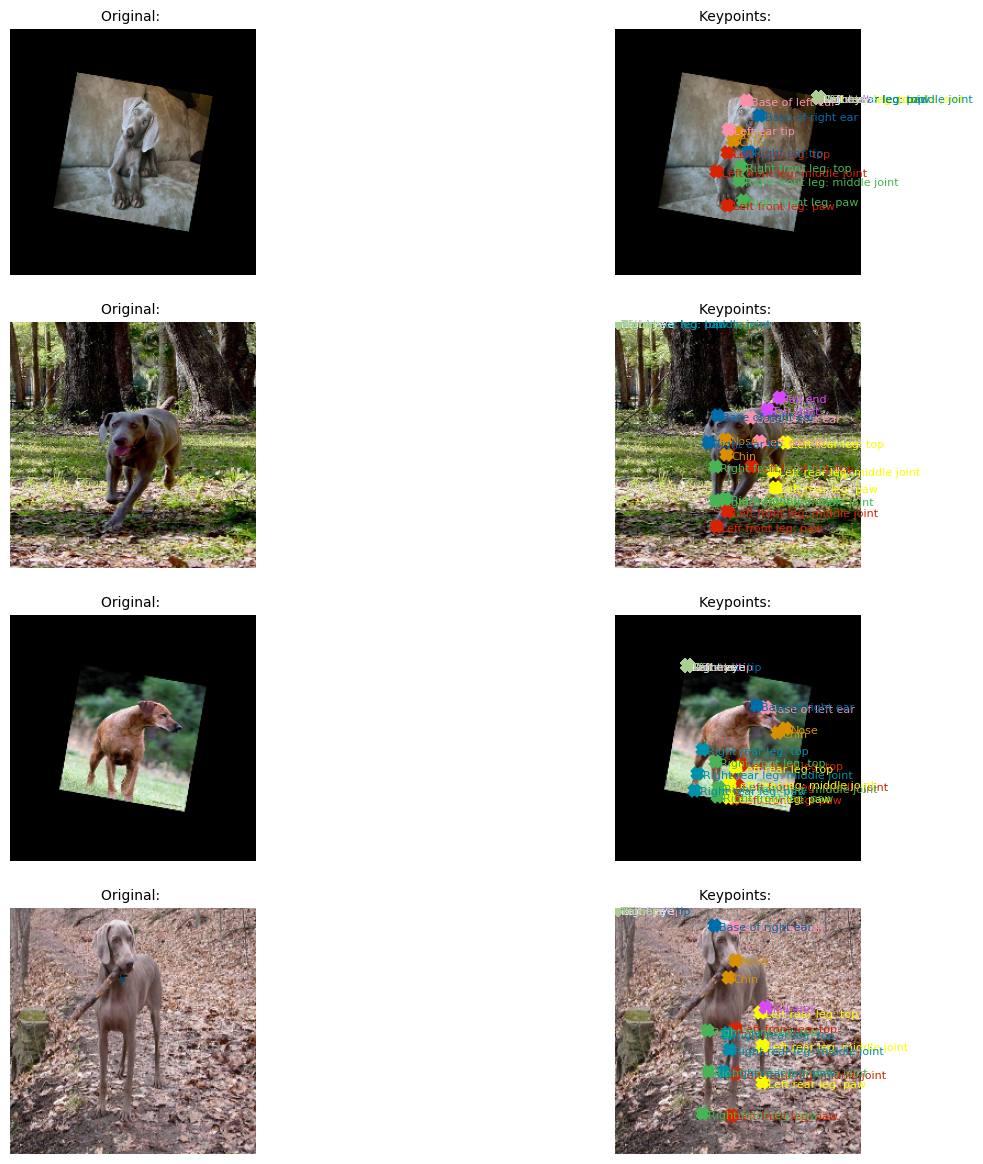

In [13]:
train_dataset = KeyPointsDataset(train_keys, train_aug, batch_size=BATCH_SIZE)
validation_dataset = KeyPointsDataset(
    validation_keys, test_aug, batch_size=BATCH_SIZE, train=False
)

print(f"Total de lotes en conjunto de entrenamiento: {len(train_dataset)}")
print(f"Total de lotes en conjunto de validación: {len(validation_dataset)}")

# Verificar que las coordenadas están correctamente normalizadas en el rango [0, 1]
sample_images, sample_keypoints = next(iter(train_dataset))
assert sample_keypoints.max() <= 1.0
assert sample_keypoints.min() >= 0.0

# Visualizar 4 muestras del generador de entrenamiento
sample_keypoints = sample_keypoints[:4].reshape(-1, 24, 2) * IMG_SIZE
visualize_keypoints(sample_images[:4], sample_keypoints)

---

## 🧠 Paso 11 — Construcción del modelo

### Aprendizaje por transferencia

El **aprendizaje por transferencia** (*transfer learning*) consiste en reutilizar un modelo preentrenado en una tarea como punto de partida para una tarea diferente. En lugar de entrenar una red desde cero (lo que requeriría millones de imágenes y días de cómputo), tomamos las características que una red ya aprendió y las adaptamos a nuestro problema.

### ¿Por qué MobileNetV2?

Usamos **MobileNetV2** preentrenado en **ImageNet-1k** como red base por varias razones:

1. **Conocimiento previo relevante:** El Stanford Dogs Dataset fue construido a partir de ImageNet, por lo que MobileNetV2 ya "conoce" perros de muchas razas y ha aprendido a detectar sus características visuales.
2. **Eficiencia:** MobileNetV2 fue diseñado para ser liviano y eficiente, ideal para experimentos rápidos.
3. **Disponibilidad:** Está incluido directamente en Keras.

### Arquitectura del modelo

```
Entrada (224×224×3)
    ↓
Preprocesamiento MobileNetV2
    ↓
MobileNetV2 (congelado, pesos ImageNet)
    ↓
Dropout (0.3) — regularización
    ↓
SeparableConv2D(48 filtros, kernel 5×5, ReLU)
    ↓
SeparableConv2D(48 filtros, kernel 3×3, Sigmoid) → Salida (1×1×48)
```

### Red completamente convolucional

La red es **completamente convolucional** (no tiene capas densas/*fully-connected* al final). Esto tiene ventajas:
- Menos parámetros que una versión con capas densas equivalentes.
- La salida `(None, 1, 1, 48)` mapea directamente a nuestros 48 valores de coordenadas normalizadas.
- La función de activación **Sigmoid** en la última capa garantiza que las salidas estén en `[0, 1]`, consistente con nuestra normalización de coordenadas.

In [14]:
def get_model():
    # Cargar los pesos preentrenados de MobileNetV2 y congelarlos.
    backbone = keras.applications.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
    )
    backbone.trainable = False

    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = keras.applications.mobilenet_v2.preprocess_input(inputs)
    x = backbone(x)
    x = layers.Dropout(0.3)(x)
    x = layers.SeparableConv2D(
        NUM_KEYPOINTS, kernel_size=5, strides=1, activation="relu"
    )(x)
    outputs = layers.SeparableConv2D(
        NUM_KEYPOINTS, kernel_size=3, strides=1, activation="sigmoid"
    )(x)

    return keras.Model(inputs, outputs, name="detector_puntos_clave")

### Inspección del resumen del modelo

Ejecuta la siguiente celda para ver la arquitectura completa. Presta atención a:
- El número total de parámetros del modelo.
- Cuántos parámetros son **entrenables** (nuestras capas de regresión) vs. **no entrenables** (backbone congelado).
- La forma de la salida: debería ser `(None, 1, 1, 48)`.

In [15]:
get_model().summary()

      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

 589824/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

4333568/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

8871936/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "detector_puntos_clave"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 7, 1280)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 3, 3, 48)       │        93,488 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 1, 1, 48)       │         2,784 │
│ (SeparableConv2D)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,354,256 (8.98 MB)

 Trainable params: 96,272 (376.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### ¿Por qué la forma de salida es `(None, 1, 1, 48)`?

La forma `(None, 1, 1, 48)` significa:
- **None:** Tamaño de lote (variable).
- **1, 1:** Dimensiones espaciales reducidas a 1×1 por las capas convolucionales.
- **48:** Los 48 valores de salida (24 puntos × 2 coordenadas).

Por eso en el generador de datos almacenamos los puntos clave con `reshape(1, 1, 24 * 2)`: para que coincidan con esta forma de salida al calcular la pérdida durante el entrenamiento.

---

## 🚀 Paso 12 — Compilación y entrenamiento del modelo

### Función de pérdida: Error Cuadrático Medio (MSE)

Usamos **MSE** (*Mean Squared Error*) como función de pérdida porque este es un problema de **regresión** (predecir valores continuos, no clases). El MSE penaliza fuertemente las predicciones muy alejadas del valor real, lo que motiva al modelo a hacer predicciones precisas.

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

### Optimizador: Adam

**Adam** es uno de los optimizadores más utilizados en deep learning. Combina las ventajas de los optimizadores *Momentum* y *RMSprop*, adaptando la tasa de aprendizaje para cada parámetro individualmente. Usamos una tasa de aprendizaje de `1e-4` (0.0001).

> ⏱️ **Tiempo de entrenamiento:** Con solo 5 épocas, el entrenamiento será rápido pero el modelo no alcanzará su máximo rendimiento. Esto es suficiente para validar que la arquitectura funciona correctamente.

In [16]:
model = get_model()
model.compile(loss="mse", optimizer=keras.optimizers.Adam(1e-4))
model.fit(train_dataset, validation_data=validation_dataset, epochs=EPOCHS)

Epoch 1/5


1/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - loss: 0.0894

4/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0917

5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 183ms/step - loss: 0.0992 - val_loss: 0.1129


Epoch 2/5


...

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0996 - val_loss: 0.1124


Epoch 5/5


1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.1017

4/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0949

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0954 - val_loss: 0.1122


---
## 💾 Paso 12b — Guardado del modelo entrenado

Una vez entrenado el modelo, lo guardamos en disco en formato `.keras` (Keras 3). Este archivo lo usará la aplicación **Streamlit** para hacer predicciones sin necesidad de re-entrenar.

El modelo se guarda en: `modelos/modelo_puntos_clave.keras`

In [17]:
import os
os.makedirs("modelos", exist_ok=True)
MODEL_PATH = "modelos/modelo_puntos_clave.keras"
model.save(MODEL_PATH)
print(f"✅ Modelo guardado en: {MODEL_PATH}")
print(f"Tamaño: {os.path.getsize(MODEL_PATH)/1e6:.2f} MB")

✅ Modelo guardado en: modelos/modelo_puntos_clave.keras
Tamaño: 10.78 MB


---

## 🎯 Paso 13 — Predicciones y visualización de resultados

Una vez entrenado el modelo, lo evaluamos visualmente comparando:
- Las anotaciones **reales** (*ground truth*) del conjunto de validación.
- Las **predicciones** del modelo sobre las mismas imágenes.

Esta comparación visual nos da una intuición inmediata de cuán bien está funcionando el modelo. Un buen indicador es que los puntos predichos estén cerca de los reales en las partes visibles del cuerpo del perro.

> **Recuerda:** Las predicciones del modelo están en el rango `[0, 1]` (normalizadas), por lo que debemos multiplicarlas por `IMG_SIZE` para obtener las coordenadas en píxeles.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 528ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 537ms/step


Puntos clave reales (Ground Truth):


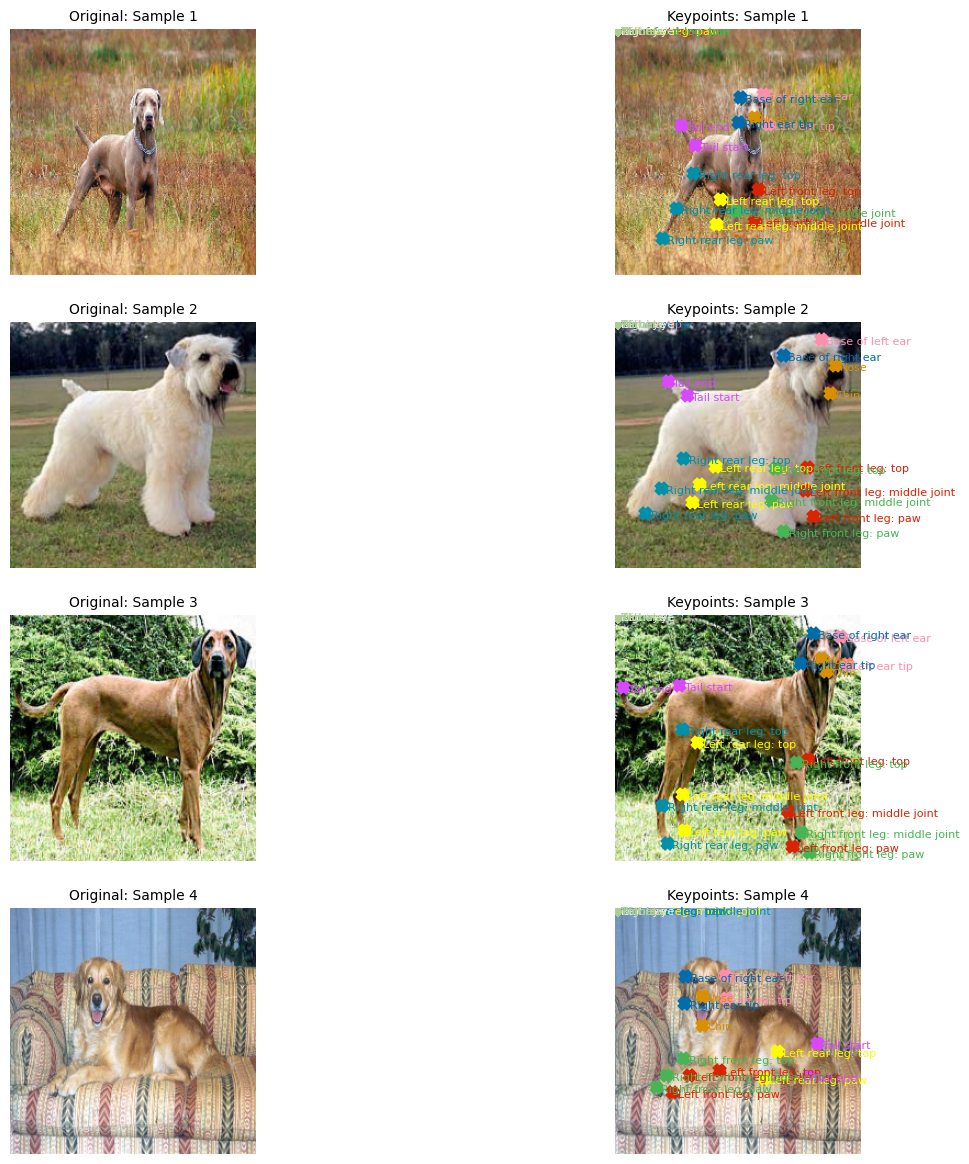

Predicciones del modelo:


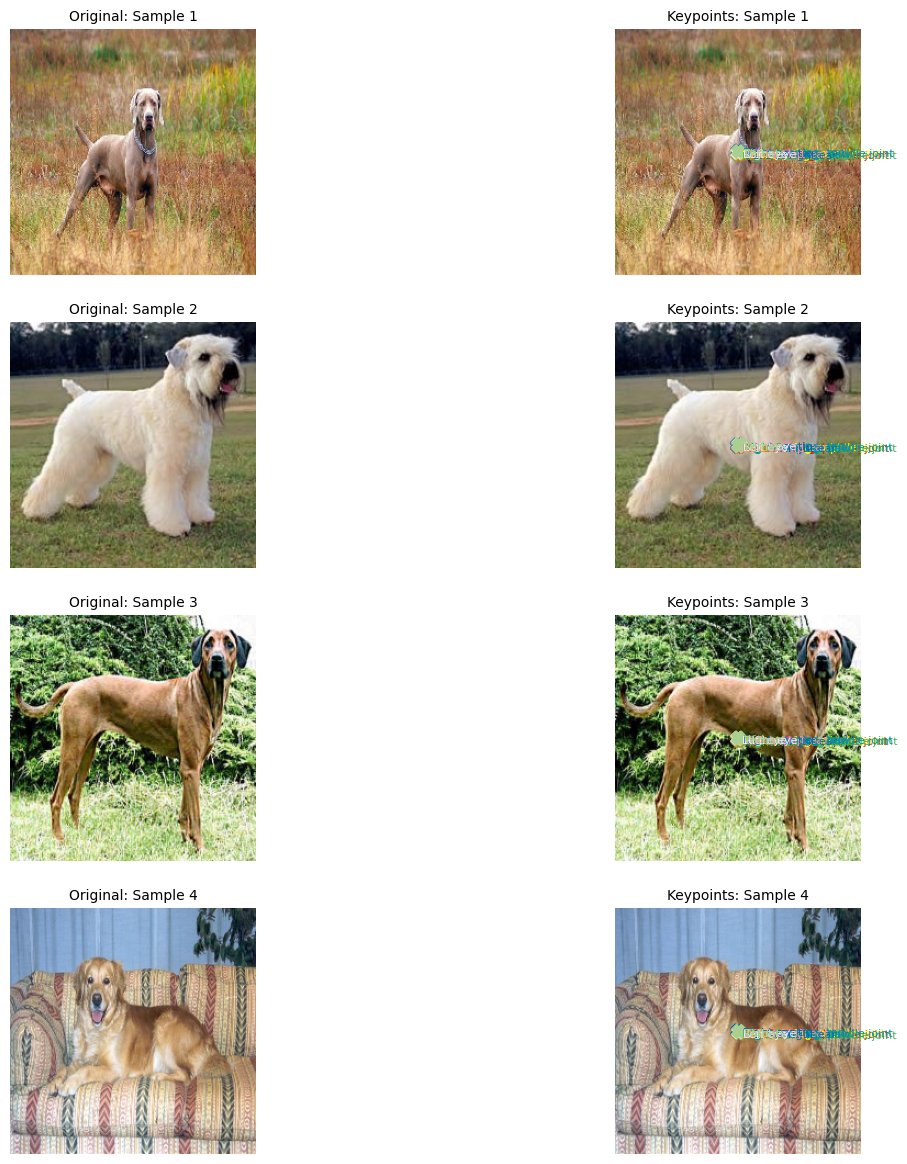

In [18]:
sample_val_images, sample_val_keypoints = next(iter(validation_dataset))
sample_val_images = sample_val_images[:4]
sample_val_keypoints = sample_val_keypoints[:4].reshape(-1, 24, 2) * IMG_SIZE
predictions = model.predict(sample_val_images).reshape(-1, 24, 2) * IMG_SIZE

# Crear títulos para la visualización
titles_gt = [f"Sample {i + 1}" for i in range(len(sample_val_images))]

# Visualizar anotaciones reales
print("Puntos clave reales (Ground Truth):")
visualize_keypoints(sample_val_images, sample_val_keypoints, titles=titles_gt)

# Visualizar predicciones del modelo
print("Predicciones del modelo:")
visualize_keypoints(sample_val_images, predictions, titles=titles_gt)

### Interpretación de los resultados

Con solo 5 épocas de entrenamiento, es probable que las predicciones no sean perfectas, pero deberían mostrar una tendencia correcta: los puntos predichos deberían estar aproximadamente en las zonas correctas del cuerpo del perro.

Entrenar por más épocas (y con el dataset completo de 12,000 imágenes) mejorará progresivamente los resultados.

---

## 🔧 Para seguir aprendiendo

Una vez que hayas completado este cuaderno, te proponemos los siguientes desafíos para profundizar:

### Experimentos de aumento de datos
Prueba diferentes transformaciones de `imgaug` en `train_aug` e investiga cómo afectan el rendimiento:
- `iaa.GaussianBlur()` — desenfoque gaussiano.
- `iaa.AdditiveGaussianNoise()` — ruido aleatorio.
- `iaa.Crop(percent=(0, 0.1))` — recorte aleatorio.

### Fine-tuning del backbone
En este cuaderno **congelamos** el backbone MobileNetV2 (no actualizamos sus pesos). Prueba **descongelar** las últimas capas y hacer *fine-tuning*:
```python
backbone.trainable = True
# Opcionalmente, congelar solo las primeras capas:
for layer in backbone.layers[:-20]:
    layer.trainable = False
```
Consulta la [guía de transfer learning de Keras](https://keras.io/guides/transfer_learning/) para más detalles.

### Otras arquitecturas
Prueba reemplazar MobileNetV2 por otras arquitecturas como:
- `keras.applications.EfficientNetB0` — más preciso pero más pesado.
- `keras.applications.ResNet50` — clásico y robusto.
- `keras.applications.MobileNetV3Small` — más eficiente que V2.

### ⏳ Más épocas de entrenamiento
Entrena el modelo durante 20, 50 o 100 épocas y monitorea cómo evoluciona la pérdida de validación. Agrega callbacks como `EarlyStopping` y `ReduceLROnPlateau` para un entrenamiento más inteligente.

---

## 📖 Recursos adicionales

- **Dataset StanfordExtra:** [GitHub (`benjiebob/StanfordExtra`)](https://github.com/benjiebob/StanfordExtra)
- **Documentación imgaug:** [imgaug.readthedocs.io](https://imgaug.readthedocs.io/)
- **Guía de Transfer Learning en Keras:** [keras.io](https://keras.io/guides/transfer_learning/)
- **MobileNetV2 - Artículo original:** [arxiv.org](https://arxiv.org/abs/1801.04381)

---

*Adaptación al español realizada por **Alfredo Díaz Claro**, 2026.*  
*Material de autoestudio — Visión por Computador con Deep Learning.*

---
## 🔍 Paso 15 — Diagnóstico: ¿por qué los puntos salían todos en el mismo sitio?

Al desplegar el modelo del cuaderno, la app mostraba **un solo punto** en lugar de 24.
La medición sobre las 25 imágenes de muestra dio:

| Síntoma | Medición |
|---|---|
| Dispersión de los 24 puntos | **0,33 %** de la imagen → todos dentro de un mismo píxel |
| Error frente a la anotación real | **27,4 %** de la imagen (equivale a predecir el promedio) |
| Pérdida final del entrenamiento | **0,095** en coordenadas normalizadas `[0,1]` |

**Causa 1 — el modelo no alcanzó a aprender.** 5 épocas, `lr = 1e-4`, backbone congelado y
solo 25 imágenes: el gradiente apenas mueve la cabeza de regresión, así que la red se queda
en la solución trivial (predecir el promedio del dataset). Una pérdida de 0,095 en `[0,1]`
significa un error típico de ±0,3 → 30 % del tamaño de la imagen.

**Causa 2 — el aumento de datos etiqueta mal el 30 % de las muestras.** `iaa.Fliplr(0.3)`
voltea la imagen pero **no** intercambia las etiquetas: la pata *izquierda* del perro
volteado sigue llamándose *izquierda*. En `entrenar_modelo.py` el volteo ahora aplica la
permutación `[0↔6, 1↔7, 2↔8, 3↔9, 4↔10, 5↔11, 14↔15, 18↔19, 20↔21]`.

**Causa 3 — los puntos sin anotar contaminan el aprendizaje.** En la muestra de
StanfordExtra, los puntos **20-23** (ojo izquierdo, ojo derecho, cruz y garganta) aparecen
**siempre** con visibilidad 0: solo existen en el subconjunto *Animal-Pose*. El cuaderno los
entrena igual que el resto (como si estuvieran en `(0,0)`), así que el modelo aprende a
mandarlos a la esquina y **el contorno se estira hacia el cielo**. Otros puntos quedan
simplemente ocultos en cada foto (una pata tapada, la cola fuera de cuadro) y no hay forma
de saberlo sin modelar la visibilidad.

> 🔎 Comprobación: `json_dict[...]["joints"][20:24]` → `[[0,0,0], [0,0,0], [0,0,0], [0,0,0]]`
> en las 25 imágenes.


---
## 🛠️ Paso 16 — Mejoras aplicadas al entrenamiento

El reentrenamiento completo está en **`entrenar_modelo.py`** (reproducible, ~4 minutos en CPU).
Mantiene la misma arquitectura del cuaderno para que la comparación sea justa:

```
Entrada 224×224×3
  → preprocess_input (MobileNetV2)
  → MobileNetV2 · ImageNet · SOLO EL ÚLTIMO BLOQUE entrenable   ← cambio 1
  → Dropout(0.3)
  → SeparableConv2D(72, 5×5, ReLU)
  → SeparableConv2D(72, 3×3, Sigmoid)  → 1×1×72                 ← cambio 4
        ├── 48 coordenadas (24 puntos × x, y)
        └── 24 visibilidades
```

| # | Cambio | Por qué |
|---|---|---|
| 1 | Descongelar el último bloque de MobileNetV2 (`block_16_expand` en adelante) | Con el backbone 100 % congelado y 25 imágenes, la cabeza no tiene capacidad para corregir las características |
| 2 | Volteo horizontal con intercambio de etiquetas izquierda/derecha | Elimina el ruido de etiquetas del pipeline original |
| 3 | Pérdida enmascarada por visibilidad `MSE·m + BCE` | No se entrena un punto del que no hay anotación; y la red aprende a **avisar** cuándo no ve un punto |
| 4 | Cabeza de 72 salidas (48 + 24) | Permite que la app dibuje solo lo que el modelo realmente localiza, y que el contorno no se deforme |

Función de pérdida:

```python
def perdida(y_true, y_pred):
    yc, yv = y_true[..., :48], y_true[..., 48:]     # coordenadas / visibilidad reales
    pc, pv = y_pred[..., :48], y_pred[..., 48:]
    m = tf.repeat(yv, 2, axis=-1)                   # máscara (x,y) por punto
    mse = tf.reduce_sum(m * tf.square(pc - yc)) / (tf.reduce_sum(m) + 1e-6)
    bce = tf.reduce_mean(keras.losses.binary_crossentropy(yv, pv))
    return mse + 0.5 * bce
```

Aumento de datos (geometría consistente entre imagen y etiquetas): rotación ±12°,
escala 0,85–1,15, traslación ±5 %, volteo con permutación, brillo 0,75–1,25 y contraste
0,8–1,2. Se generan **60 variantes por imagen** (1.500 muestras) y se entrena 160 épocas con
AdamW (`lr = 1e-3`, `wd = 1e-4`).

> 💡 **Truco de velocidad:** las activaciones de la parte congelada se calculan **una sola vez**
> y se guardan en un arreglo (`feat_extractor.predict`). Entrenar sobre ese caché es
> matemáticamente equivalente a entrenar de punta a punta, pero baja de ~30 s a ~1 s por época.


---
## ✅ Paso 17 — Resultados y conclusiones

### Antes vs. después (25 imágenes de muestra, puntos visibles)

| Métrica | Cuaderno original | Reentrenado |
|---|---|---|
| Error medio vs. anotación real | 27,44 % de la imagen | **7,94 %** |
| Error mediano | 25,95 % | **7,32 %** |
| Dispersión del esqueleto | 0,33 % (colapso) | **31,27 %** |
| Acierto de visibilidad (20 puntos anotados) | — | **100,00 %** |
| Pérdida final | 0,095 | **≈ 0,0006** |

Figuras generadas por `evaluar_modelo.py`:

* `resultados/figura_predicciones.png` — las 25 muestras con los puntos y el contorno.
* `resultados/figura_comparacion.png` — original · predicción · anotación real.
* `resultados/metricas.txt` — métricas por imagen.

### Qué significa el contorno de la app

El modelo **no** hace segmentación: predice puntos. El borde azul es la **envolvente
convexa de los puntos que el modelo considera visibles**, suavizada con el algoritmo de
Chaikin (3 iteraciones) y dibujada con halo y supermuestreo ×3 para que no salga escalonada.
Con 14–20 puntos bien localizados, esa envolvente rodea el cuerpo del perro; si un punto está
mal, la envolvente se abre (por eso se excluyen los puntos no anotados y los no visibles).

### Conclusiones

1. **El problema no era la app, era el entrenamiento.** La arquitectura del cuaderno es
   correcta; con 5 épocas y `lr = 1e-4` la red se queda en el promedio y los 24 puntos se
   dibujan uno encima de otro.
2. **La visibilidad hay que modelarla.** En un dataset con oclusiones (y con 4 puntos que
   ni siquiera están anotados), predecir solo `(x, y)` obliga al modelo a inventar
   coordenadas para partes que no se ven.
3. **El aumento de datos tiene que ser semánticamente correcto.** Voltear la imagen sin
   permutar las etiquetas izquierda/derecha entrena al modelo con etiquetas falsas.
4. **25 imágenes no alcanzan para generalizar**: el modelo acierta en perros parecidos a los
   de la muestra, pero no es un detector de producción. Con las 12.000 imágenes de
   StanfordExtra completo (o más épocas y *fine-tuning*) la precisión subiría bastante.

### Para seguir

- Dataset completo StanfordExtra (requiere solicitar acceso a los autores).
- `EarlyStopping` + `ReduceLROnPlateau` y búsqueda de hiperparámetros.
- Probar `EfficientNetB0` / `MobileNetV3` como backbone.
- Sustituir la envolvente por una **máscara de segmentación** real (p. ej. con el campo `seg`
  del dataset) si se quiere un contorno exacto.

---

### ▶️ Reproducir todo

```bash
python entrenar_modelo.py     # reentrena y guarda modelos/modelo_puntos_clave.keras
python evaluar_modelo.py      # métricas + figuras en resultados/
streamlit run app_streamlit.py
python test_app.py            # prueba E2E de la app
```
